# Capítulo 3 · Actividad: transformación, codificación y escalado

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/03_actividad_transformacion_escalado.ipynb)

Vas a aplicar lo que viste en la notebook de clase `05_transformacion_y_escalado` a **tres datasets distintos**, hasta dejar cada uno listo para un modelo.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Añade todas las celdas que necesites.
- En las celdas ✍️ **justifica tus decisiones**.
- Al terminar, ejecuta **Kernel → Restart & Run All**.

| Parte | Datos | Tema |
|---|---|---|
| A. Propinas | `data/tips.csv` | Variables nuevas, codificación y escalado a mano |
| B. Pingüinos | `data/penguins.csv` | Codificación y escalado con scikit-learn |
| C. Viviendas de California | `data/california_housing.csv` | `Pipeline` completo |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)

# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

---
## Parte A · Propinas 💵

Usaremos el dataset de propinas: `total_bill` (cuenta), `tip` (propina), `sex`, `smoker`, `day` (`Thur`, `Fri`, `Sat`, `Sun`), `time` (`Lunch`/`Dinner`) y `size` (personas en la mesa). **Queremos predecir la propina** (`tip`).

### Ejercicio 1 · Tipos de variables

Carga los datos en `propinas` y clasifica cada columna (salvo `tip`, que es el *target*) como **numérica**, **nominal**, **binaria** u **ordinal**.

**Cómo se resuelve y por qué:** El tipo almacenado y el significado estadístico no son lo mismo: una categoría codificada como entero no se vuelve una cantidad.

In [2]:
propinas = pd.read_csv(DATA_DIR / 'tips.csv')
display(propinas.head())
display(propinas.dtypes)

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
total_bill    float64
tip           float64
sex               str
smoker            str
day               str
time              str
size            int64
dtype: object


**Respuesta explicada:**

total_bill es numérica continua; size es numérica discreta (un conteo). sex, smoker y time son binarias nominales en este dataset. day se puede tratar como nominal; tiene orden de calendario, pero ese orden no implica una relación creciente con tip. No hay una variable claramente ordinal de intensidad como pequeño/mediano/grande. tip es el objetivo numérico.

### Ejercicio 2 · Variables nuevas

a) Crea la columna `cuenta_por_persona`.

b) Un compañero propone crear también `pct_propina` (la propina como porcentaje de la cuenta) para usarla en el modelo.

**Cómo se resuelve y por qué:** La cuenta por persona usa información que puede estar disponible antes de conocer la propina. La disponibilidad real depende del momento de predicción.

In [3]:
propinas['cuenta_por_persona'] = propinas['total_bill'] / propinas['size']
display(propinas[['total_bill', 'size', 'cuenta_por_persona']].head())

   total_bill  size  cuenta_por_persona
0       16.99     2            8.495000
1       10.34     3            3.446667
2       21.01     3            7.003333
3       23.68     2           11.840000
4       24.59     4            6.147500


✍️ **Pregunta:** ¿se puede usar `pct_propina` como variable para predecir la propina? ¿Por qué?

**Respuesta explicada:**

No: pct_propina = 100·tip/total_bill incluye el objetivo tip. Al predecir una propina desconocida tampoco conocemos ese porcentaje. Usarlo produciría fuga de información y una evaluación artificialmente buena.

### Ejercicio 3 · Variables binarias

Convierte `sex`, `smoker` y `time` en columnas de 0 y 1, guardando el resultado en columnas nuevas (`sex_num`, `smoker_num`, `time_num`).

**Cómo se resuelve y por qué:** La elección de 0 y 1 es convencional y queda explícita. Conservamos las columnas de texto para poder comprobar la traducción.

In [4]:
propinas['sex_num'] = propinas['sex'].map({'Female': 0, 'Male': 1})
propinas['smoker_num'] = propinas['smoker'].map({'No': 0, 'Yes': 1})
propinas['time_num'] = propinas['time'].map({'Lunch': 0, 'Dinner': 1})
display(propinas[['sex_num', 'smoker_num', 'time_num']].head())

   sex_num  smoker_num  time_num
0        0           0         1
1        1           0         1
2        1           0         1
3        1           0         1
4        0           0         1


### Ejercicio 4 · El día: ¿one-hot u ordinal?

a) Codifica `day` con one-hot, con y sin `drop_first`.

b) Codifica `day` de forma ordinal respetando el orden de la semana.

**Cómo se resuelve y por qué:** One-hot asigna una columna a cada día. El ordinal impone posiciones consecutivas, lo que puede añadir una relación numérica que el problema no justifica.

In [5]:
day_onehot = pd.get_dummies(propinas['day'], prefix='day', dtype=int)
day_reducido = pd.get_dummies(propinas['day'], prefix='day', drop_first=True, dtype=int)
propinas['day_ordinal'] = propinas['day'].map({'Thur': 0, 'Fri': 1, 'Sat': 2, 'Sun': 3})
display(day_onehot.head())
display(day_reducido.head())
print('Día eliminado:', set(day_onehot.columns) - set(day_reducido.columns))

   day_Fri  day_Sat  day_Sun  day_Thur
0        0        0        1         0
1        0        0        1         0
2        0        0        1         0
3        0        0        1         0
4        0        0        1         0
   day_Sat  day_Sun  day_Thur
0        0        1         0
1        0        1         0
2        0        1         0
3        0        1         0
4        0        1         0
Día eliminado: {'day_Fri'}


✍️ **Pregunta:** ¿qué codificación elegirías para `day` y por qué? ¿Y en `drop_first=True`, qué día se eliminó y cómo se reconoce una fila de ese día?

**Respuesta explicada:**

Elegiría one-hot para no suponer que un día tiene mayor efecto que otro por su posición. Con el orden de categorías observado se elimina Fri (day_Fri): una fila de viernes tiene ceros en todas las columnas de día restantes. drop_first puede evitar dependencia lineal si se usa una regresión con intercepto; no siempre es necesario para otros modelos.

### Ejercicio 5 · Escalado a mano

Escala `total_bill` con **min-max** y con **z-score**, sin usar scikit-learn. Comprueba con `describe()` la media, la desviación, el mínimo y el máximo de cada versión.

**Cómo se resuelve y por qué:** Min-max lleva el mínimo a 0 y el máximo a 1. z-score centra en cero y divide por la desviación poblacional, igual que StandardScaler. describe usa ddof=1, por eso mostrará una desviación ligeramente superior a 1.

In [6]:
cuenta = propinas['total_bill']
escalado_manual = pd.DataFrame({'original': cuenta,
    'minmax': (cuenta-cuenta.min())/(cuenta.max()-cuenta.min()),
    'zscore': (cuenta-cuenta.mean())/cuenta.std(ddof=0)})
display(escalado_manual.describe())
print('Desviación poblacional:', escalado_manual.std(ddof=0))
assert np.isclose(escalado_manual['zscore'].std(ddof=0), 1)

         original      minmax        zscore
count  244.000000  244.000000  2.440000e+02
mean    19.785943    0.350145 -7.871663e-17
std      8.902412    0.186477  1.002056e+00
min      3.070000    0.000000 -1.881547e+00
25%     13.347500    0.215281 -7.247111e-01
50%     17.795000    0.308442 -2.241005e-01
75%     24.127500    0.441087  4.886857e-01
max     50.810000    1.000000  3.492068e+00
Desviación poblacional: original    8.884151
minmax      0.186094
zscore      1.000000
dtype: float64


### Ejercicio 6 · Logaritmo

a) Calcula la asimetría de `total_bill` y de `np.log1p(total_bill)`.

b) Dibuja sus dos histogramas, uno al lado del otro.

**Cómo se resuelve y por qué:** log1p comprime los valores altos más que los bajos. A diferencia del escalado lineal, puede cambiar la forma de la distribución.

Asimetría original: 1.1332130376158205
Asimetría log1p: -0.010800869997070795


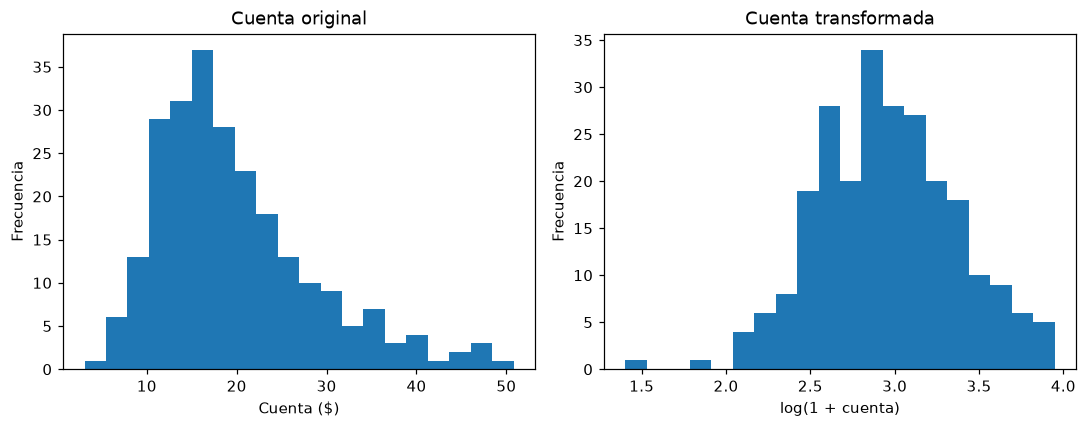

In [7]:
print('Asimetría original:', cuenta.skew())
print('Asimetría log1p:', np.log1p(cuenta).skew())
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(cuenta, bins=20)
axes[0].set(title='Cuenta original', xlabel='Cuenta ($)', ylabel='Frecuencia')
axes[1].hist(np.log1p(cuenta), bins=20)
axes[1].set(title='Cuenta transformada', xlabel='log(1 + cuenta)', ylabel='Frecuencia')
plt.tight_layout()
plt.show()

✍️ **Pregunta:** si escalaras `total_bill` con z-score en lugar de aplicarle el logaritmo, ¿cambiaría su asimetría? ¿Por qué?

**Respuesta explicada:**

No: restar una constante y dividir por una desviación positiva conserva la asimetría (1.133). log1p sí cambia la forma y aquí la lleva a -0.011. Escalar unidades no equivale a corregir una cola larga.

---
## Parte B · Pingüinos 🐧 (con scikit-learn)

Queremos predecir la **especie** de un pingüino a partir de sus medidas, la isla y el sexo.

### Ejercicio 7 · Preparar y separar

a) Carga `penguins.csv` en `pinguinos` y elimina las filas con valores faltantes.

b) Separa `X` (todas las columnas salvo `species`) e `y` (`species`).

c) Divide en train y test (20% para test, `random_state=42`). ¿Cuántas filas tiene cada parte?

**Cómo se resuelve y por qué:** Separamos antes de aprender parámetros para que test simule datos nuevos. Eliminamos filas con cualquier nulo según lo solicitado; esto conserva 333 casos.

In [8]:
pinguinos = pd.read_csv(DATA_DIR / 'penguins.csv').dropna()
X = pinguinos.drop(columns='species')
y = pinguinos['species']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = X_train.copy()
X_test = X_test.copy()
print('Filas completas:', len(pinguinos), 'Train:', len(X_train), 'Test:', len(X_test))

Filas completas: 333 Train: 266 Test: 67


### Ejercicio 8 · `OneHotEncoder`

a) Ajusta un `OneHotEncoder` con la columna `island` de **train** y muestra las categorías que aprendió.

b) Transforma este DataFrame con dos pingüinos nuevos: uno de `Dream` y otro de la isla `Anvers`.
```python
nuevos = pd.DataFrame({"island": ["Dream", "Anvers"]})
```

**Cómo se resuelve y por qué:** fit aprende categorías solo de train. sparse_output=False permite devolver un DataFrame con la configuración de salida pandas del notebook.

In [9]:
encoder_isla = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder_isla.fit(X_train[['island']])
print('Categorías:', encoder_isla.categories_)
nuevos = pd.DataFrame({'island': ['Dream', 'Anvers']})
display(encoder_isla.transform(nuevos))

Categorías: [array(['Biscoe', 'Dream', 'Torgersen'], dtype=object)]
   island_Biscoe  island_Dream  island_Torgersen
0            0.0           1.0               0.0
1            0.0           0.0               0.0


✍️ **Pregunta:** ¿qué pasó con el pingüino de `Anvers`? ¿Qué habría pasado sin `handle_unknown="ignore"`?

**Respuesta explicada:**

Anvers no estaba en train y se representa con ceros en todas las columnas de isla. Sin handle_unknown="ignore", transform lanzaría un error por categoría desconocida. Estos ceros no significan que Anvers sea idéntica a una isla conocida.

### Ejercicio 9 · `OrdinalEncoder`

a) Crea en `X_train` una columna de texto `tamaño` agrupando `body_mass_g` en `"pequeño"` (hasta 3500 g), `"mediano"` (hasta 4500 g) y `"grande"` (más de 4500 g).

b) Codifícala con un `OrdinalEncoder` **sin indicar** el orden y muestra las categorías que aprendió.

c) Vuelve a codificarla indicando el orden correcto.

**Cómo se resuelve y por qué:** Los intervalos incluyen su borde superior. Especificar categories evita que el orden alfabético sustituya al orden de tamaño.

In [10]:
X_train['tamaño'] = pd.cut(X_train['body_mass_g'], bins=[-np.inf,3500,4500,np.inf], labels=['pequeño','mediano','grande']).astype(str)
ordinal_auto = OrdinalEncoder()
display(ordinal_auto.fit_transform(X_train[['tamaño']]).head())
print('Orden automático:', ordinal_auto.categories_)
ordinal_correcto = OrdinalEncoder(categories=[['pequeño','mediano','grande']])
display(ordinal_correcto.fit_transform(X_train[['tamaño']]).head())
print('Orden correcto:', ordinal_correcto.categories_)

     tamaño
230     0.0
84      2.0
303     0.0
22      1.0
29      1.0
Orden automático: [array(['grande', 'mediano', 'pequeño'], dtype=object)]
     tamaño
230     2.0
84      0.0
303     2.0
22      1.0
29      1.0
Orden correcto: [array(['pequeño', 'mediano', 'grande'], dtype=object)]


✍️ **Pregunta:** ¿qué número recibe cada tamaño en b)? ¿Por qué es un problema?

**Respuesta explicada:**

Sin indicar orden: grande=0, mediano=1 y pequeño=2, porque se ordenan alfabéticamente. Esto invierte la interpretación numérica del tamaño. El orden solicitado es pequeño=0, mediano=1 y grande=2; sigue siendo una categoría ordinal, no una medida con distancias físicas iguales.

### Ejercicio 10 · `StandardScaler`

Estandariza las cuatro medidas numéricas (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`) de la forma correcta y compara la media de cada columna en train y en test.

**Cómo se resuelve y por qué:** fit_transform aprende media y desviación de train; transform reutiliza esas mismas referencias en test. Ajustar otro scaler al test sería incorrecto.

In [11]:
medidas = ['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']
scaler = StandardScaler()
train_escalado = scaler.fit_transform(X_train[medidas])
test_escalado = scaler.transform(X_test[medidas])
display(pd.DataFrame({'media_train': train_escalado.mean(), 'media_test': test_escalado.mean()}))
assert np.allclose(train_escalado.mean(), 0, atol=1e-12)

                    media_train  media_test
bill_length_mm    -2.086885e-17   -0.101540
bill_depth_mm      1.101875e-15    0.009018
flipper_length_mm -1.419082e-17   -0.011820
body_mass_g        9.182296e-17   -0.047449


✍️ **Pregunta:** ¿por qué la media en test no es exactamente 0? ¿Es un error?

**Respuesta explicada:**

No es un error. El test contiene otros pingüinos y su media original no coincide exactamente con la de train. Su media transformada es (media_test − media_train) / desviación_train; centrarlo por separado ocultaría diferencias y usaría información del conjunto de evaluación.

### Ejercicio 11 · `ColumnTransformer`

Construye un `ColumnTransformer` que:
- estandarice las cuatro medidas numéricas,
- aplique one-hot a `island` y `sex` (con una sola columna para `sex`).

Ajústalo con train, transforma train y test, y muestra la forma y las primeras filas del resultado.

**Cómo se resuelve y por qué:** Cada grupo de columnas recibe una transformación. Sexo conserva una columna con drop=if_binary; isla conserva sus tres columnas. La columna didáctica tamaño se descarta explícitamente y no es necesaria para predecir un pingüino nuevo.

In [12]:
preprocesador = ColumnTransformer([
    ('numericas', StandardScaler(), medidas),
    ('isla', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['island']),
    ('sexo', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), ['sex'])
], remainder='drop')
X_train_preparado = preprocesador.fit_transform(X_train)
X_test_preparado = preprocesador.transform(X_test)
print('Formas:', X_train_preparado.shape, X_test_preparado.shape)
display(X_train_preparado.head())
display(X_test_preparado.head())

Formas: (266, 8) (67, 8)
     numericas__bill_length_mm  ...  sexo__sex_Male
230                  -0.593727  ...             0.0
84                   -1.261043  ...             0.0
303                   1.093099  ...             1.0
22                   -1.520555  ...             0.0
29                   -0.667873  ...             1.0

[5 rows x 8 columns]
     numericas__bill_length_mm  ...  sexo__sex_Male
30                   -0.853239  ...             0.0
317                   0.518466  ...             0.0
79                   -0.371288  ...             1.0
201                   1.056026  ...             0.0
63                   -0.556654  ...             1.0

[5 rows x 8 columns]


### Ejercicio 12 · Un pingüino nuevo

Prepara con tu `preprocesador` este pingüino recién medido:
```python
nuevo = pd.DataFrame([{"island": "Biscoe", "bill_length_mm": 47.5, "bill_depth_mm": 15.0,
                       "flipper_length_mm": 218.0, "body_mass_g": 5200.0, "sex": "Male"}])
```

**Cómo se resuelve y por qué:** Reutilizamos el preprocesador ya ajustado para obtener las mismas columnas y escalas. Esto prepara datos, pero todavía no entrena un clasificador ni predice especie.

In [13]:
nuevo = pd.DataFrame([{'island': 'Biscoe', 'bill_length_mm': 47.5, 'bill_depth_mm': 15.0,
    'flipper_length_mm': 218.0, 'body_mass_g': 5200.0, 'sex': 'Male'}])
nuevo_preparado = preprocesador.transform(nuevo)
display(nuevo_preparado)
assert list(nuevo_preparado.columns) == list(X_train_preparado.columns)

   numericas__bill_length_mm  ...  sexo__sex_Male
0                   0.629685  ...             1.0

[1 rows x 8 columns]


---
## Parte C · Viviendas de California 🏠 (`Pipeline` completo)

Queremos predecir el valor de las viviendas (`MedHouseVal`) de cada distrito a partir del resto de columnas: `MedInc`, `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude` y `Longitude`.

### Ejercicio 13 · ¿Qué variables transformar?

Carga `california_housing.csv` en `california` y calcula la asimetría de cada variable (salvo el *target*). Después, calcula la asimetría que tendrían las variables más asimétricas si les aplicaras `np.log1p`.

**Cómo se resuelve y por qué:** Comparamos la asimetría de variables con cola derecha y valores no negativos. Esta exploración global responde al enunciado; al preparar una evaluación debemos confirmar las decisiones usando solo train. No aplicamos log1p a Longitude, que tiene valores menores que -1.

In [14]:
california = pd.read_csv(DATA_DIR / 'california_housing.csv')
X_california = california.drop(columns='MedHouseVal')
asimetria = X_california.skew()
display(asimetria.sort_values(ascending=False))
candidatas = asimetria.index[(asimetria > 1) & (X_california.min() >= 0)].tolist()
comparacion_log = pd.DataFrame({'original': X_california[candidatas].skew(), 'log1p': np.log1p(X_california[candidatas]).skew()})
display(comparacion_log)

AveOccup      97.639561
AveBedrms     31.316956
AveRooms      20.697869
Population     4.935858
MedInc         1.646657
Latitude       0.465953
HouseAge       0.060331
Longitude     -0.297801
dtype: float64
             original     log1p
MedInc       1.646657  0.226083
AveRooms    20.697869  1.390761
AveBedrms   31.316956  8.988786
Population   4.935858 -1.044087
AveOccup    97.639561  3.879679


✍️ **Pregunta:** ¿a qué variables les aplicarías el logaritmo? ¿Funciona igual de bien en todas?

**Respuesta explicada:**

Consideraría MedInc, AveRooms, AveBedrms, Population y AveOccup: log1p reduce sus asimetrías positivas. No las vuelve igualmente simétricas: habitaciones, dormitorios y ocupación pueden conservar colas apreciables. En el siguiente ejercicio confirmaré la selección solo con train, evitando que test decida las transformaciones.

### Ejercicio 14 · El `Pipeline` completo

a) Separa `X` e `y`, y divide en train y test (20% para test, `random_state=42`).

b) Construye un preprocesador que aplique **logaritmo y después estandarización** a las variables asimétricas que elegiste, y **solo estandarización** al resto.

c) Ajústalo con train, transforma train y test, y comprueba que las medias en train son 0 y las desviaciones 1.

**Cómo se resuelve y por qué:** Pipeline aplica logaritmo y después escalado en el orden correcto. ColumnTransformer combina esa rama con otra que solo escala. Se ajustan parámetros en train y se reutilizan en test; las desviaciones se comprueban con ddof=0. El ejercicio pide preprocesamiento, no entrenar todavía un regresor.

In [15]:
X = california.drop(columns='MedHouseVal')
y = california['MedHouseVal']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# La selección final usa únicamente entrenamiento.
skew_train = X_train.skew()
candidatas_train = skew_train.index[(skew_train > 1) & (X_train.min() >= 0)].tolist()
columnas_log = [col for col in candidatas_train if abs(np.log1p(X_train[col]).skew()) < abs(skew_train[col])]
columnas_resto = [col for col in X.columns if col not in columnas_log]
print('Logaritmo:', columnas_log, 'Solo escalado:', columnas_resto)
pipeline_log = Pipeline([
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('escala', StandardScaler())])
preprocesador_california = ColumnTransformer([
    ('log_y_escala', pipeline_log, columnas_log),
    ('solo_escala', StandardScaler(), columnas_resto)])
train_final = preprocesador_california.fit_transform(X_train)
test_final = preprocesador_california.transform(X_test)
display(pd.DataFrame({'media_train': train_final.mean(), 'std_train_ddof0': train_final.std(ddof=0), 'media_test': test_final.mean()}))
print('Formas:', train_final.shape, test_final.shape)
assert np.allclose(train_final.mean(), 0, atol=1e-12)
assert np.allclose(train_final.std(ddof=0), 1)
assert np.isfinite(train_final.to_numpy()).all()
assert np.isfinite(test_final.to_numpy()).all()

Logaritmo: ['MedInc', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup'] Solo escalado: ['HouseAge', 'Latitude', 'Longitude']
                           media_train  std_train_ddof0  media_test
log_y_escala__MedInc     -4.518350e-16              1.0   -0.025891
log_y_escala__AveRooms   -1.357656e-16              1.0   -0.029159
log_y_escala__AveBedrms   7.143295e-16              1.0   -0.014585
log_y_escala__Population  3.287637e-16              1.0   -0.009071
log_y_escala__AveOccup    2.760496e-16              1.0    0.004315
solo_escala__HouseAge    -1.678244e-17              1.0    0.012379
solo_escala__Latitude     3.385750e-15              1.0   -0.026415
solo_escala__Longitude    1.776787e-15              1.0    0.031377
Formas: (16512, 8) (4128, 8)
